---
# **Cuaderno 4:**  Crossroad Mutation cancer and rare diseases
---
* Author: Melissa Ormeño; Alexis Salas
* Laboratory: Cancer Molecular Dynamics
* Date: May 2026

**Aims:**

In [1]:
#Dependences
import matplotlib.pyplot as plt
import pandas as pd
import requests
import numpy as np

## Funcion para clasificar mutaciones por dominio

In [2]:

# Target UniProt identifiers for the TGF-beta pathway genes
uniprot_ids = [
    'O00238', 'P27037', 'P36894', 'P35790', 'P36897', 'P37023',
    'P37173', 'Q04771', 'Q13705', 'Q13873', 'Q16671', 'Q8NER5'
]

def get_features(uniprot_ids):
    """
    Fetch structural and functional features from the UniProt REST API.
    
    Note: 'Topological domain' annotations are retained as they encompass 
    critical structural regions, including the kinase domain. 'Region' and 
    'Chain' annotations are excluded as they do not constitute discrete domains.
    """
    features_dict = {}
    types = ["Signal", "Transmembrane", "Domain"]
    
    for uniprot_id in uniprot_ids: 
        response = requests.get(f'https://rest.uniprot.org/uniprotkb/{uniprot_id}.json')
    
        if response.status_code == 200:
            json_data = response.json()
            gen_name = json_data['genes'][0]['geneName']['value']  # Extract canonical gene symbol
            features = json_data.get("features")

        features_dict[gen_name] = []
        
        for f in features:
            f_type = f.get("type")
            if f_type in types:
                f_start = f.get("location").get("start").get("value")
                f_end = f.get("location").get("end").get("value")
                f_description = f.get("description")
                f_domain_name = f_type if not f_description else f"{f_type}_{f_description}"
    
                # Store structural feature coordinates
                features_dict[gen_name].append({
                    "Dominio": f_domain_name,
                    "Start": int(f_start),
                    "End": int(f_end),
                })

    return features_dict

# Retrieve reference protein domain maps
data = get_features(uniprot_ids)

def clasificar_mutacion(row):
    """
    Map somatic mutations to specific functional protein domains 
    based on amino acid coordinate ranges.
    """
    gene = row['Hugo_Symbol']
    mutation = row['HGVSp_Short']

    if gene in data:
        # Extract numerical amino acid position from HGVSp string
        position = int(''.join(filter(str.isdigit, mutation)))
        
        # Intersect mutation position with structural domain coordinates
        for dominio in data[gene]:
            start = dominio["Start"]
            end = dominio["End"]
            nombre = dominio["Dominio"]
            
            if start <= position <= end:
                return pd.Series([nombre, f"{start}-{end}"])  # Returns domain name and residue range

    return pd.Series(["Otro", None])

In [19]:
# Load and preprocess cancer dataset
df_cancer = pd.read_csv("../data/TCGA/mut_missense_TCGA.csv")
#df_cancer = df_cancer.drop(columns=["Patient_ID", "Tumor_Sample_Barcode"])
df_cancer = df_cancer.dropna(subset=["HGVSp_Short"])

# Load and filter rare diseases dataset for missense variants
df_rare_diseases = pd.read_csv("../data/Mut_RareDiseases/mut_rarediseases_clean.txt", sep="\t")
missense_RD = df_rare_diseases[df_rare_diseases["Molecular consequence"] == "missense variant"]

# Identify overlapping missense mutations between cohorts
merge_miss = df_cancer.merge(
    missense_RD, 
    left_on=['Hugo_Symbol', 'HGVSp_Short'], 
    right_on=['gene_name', 'Protein change']
)

# Display overlap metrics
print(f"Genes con mutaciones overlap: {', '.join(merge_miss['Hugo_Symbol'].unique())}")
print(f"Numero de mutaciones overlap: {merge_miss.groupby('Hugo_Symbol')['HGVSp_Short'].nunique().sum()}")

# Map mutations to functional domains and coordinate ranges
merge_miss[['Dominio', "Rango"]] = merge_miss.apply(clasificar_mutacion, axis=1)
merge_miss.head(2)

Genes con mutaciones overlap: TGFBR2, BMPR2, ACVR2B, ACVR1, BMPR1A, ACVRL1
Numero de mutaciones overlap: 15


,Patient_ID,Tumor_Sample_Barcode,Hugo_Symbol,Chromosome,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,HGVSc,HGVSp_Short,...,Germline classification,GRCh38Chromosome,GRCh38Location,VariationID,AlleleID(s),dbSNP ID,Canonical SPDI,Orphanet_Match,Dominio,Rango
0,TCGA-D5-6931,TCGA-D5-6931-TUMOR,TGFBR2,chr3,Missense_Mutation,Single base substitution,C,T,chr3:g.30691477C>T,R528C,...,Pathogenic,30.0,30691477,12512,27551,rs104893810,NC_000003.12:30691476:C:T,Sin coincidencias,Domain_Protein kinase,244-544
1,TCGA-D5-6931,TCGA-D5-6931-TUMOR,TGFBR2,chr3,Missense_Mutation,Single base substitution,C,T,chr3:g.30691477C>T,R528C,...,Pathogenic,30.0,30691477,12512,27551,rs104893810,NC_000003.12:30691476:C:T,Loeys-Dietz syndrome,Domain_Protein kinase,244-544


In [20]:
df_cancer[['Dominio', "Rango"]] = df_cancer.apply(clasificar_mutacion, axis=1)
df_cancer.head(2)

,Patient_ID,Tumor_Sample_Barcode,Hugo_Symbol,Chromosome,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,HGVSc,HGVSp_Short,HGVSp,Project_ID,cancer_type,Dominio,Rango
0,TCGA-BH-A0HF,TCGA-BH-A0HF-TUMOR,ACVR2A,chr2,Missense_Mutation,Single base substitution,C,T,chr2:g.147915234C>T,P83L,p.?,TCGA-BRCA,Breast,Otro,None
1,TCGA-E9-A2JT,TCGA-E9-A2JT-TUMOR,ACVRL1,chr12,Missense_Mutation,Single base substitution,G,A,chr12:g.51914483G>A,E50K,p.?,TCGA-BRCA,Breast,Otro,None


## Crossroad missense mutation

In [21]:
from matplotlib_venn import venn2

# Define dataset inputs
df1 = miss_mut
col_gen_df1 = "Hugo_Symbol"
col_mutation_df1 = "HGVSp_Short"

df2 = missense_RD
col_gen_df2 = "gene_name"
col_mutation_df2 = "Protein change"

# Generate unique mutation-gene coordinate sets
mutaciones_df1 = set(df1.apply(lambda x: (x[col_mutation_df1], x[col_gen_df1]), axis=1).dropna())
mutaciones_df2 = set(df2.apply(lambda x: (x[col_mutation_df2], x[col_gen_df2]), axis=1).dropna())

# Calculate absolute metrics
total_mutaciones_df1 = len(mutaciones_df1)
total_mutaciones_df2 = len(mutaciones_df2)

# Generate Venn diagram
plt.figure(figsize=(8, 6))
venn_plot = venn2(
    [mutaciones_df1, mutaciones_df2], 
    set_labels=('Cancer', 'Rare Diseases'), 
    set_colors=('#e580ff33', '#5599ff3b')
)

# Configure plot annotations
plt.title("Shared Mutations Between Cancer and Rare Diseases", fontsize=14, pad=20, weight='bold')
plt.text(-0.9, 0.5, f'Cancer Mutations: {total_mutaciones_df1}', fontsize=11, ha='left')
plt.text(0.9, 0.4, f'Rare Disease Mutations: {total_mutaciones_df2}', fontsize=11, ha='right')

# Export vector-compatible graphic
plt.savefig("../pictures/ven_merge_missense.png", format='png', dpi=600, bbox_inches='tight')
plt.savefig("../pictures/ven_merge_missense.svg")
plt.show()

NameError: name 'miss_mut' is not defined

## Graficos 

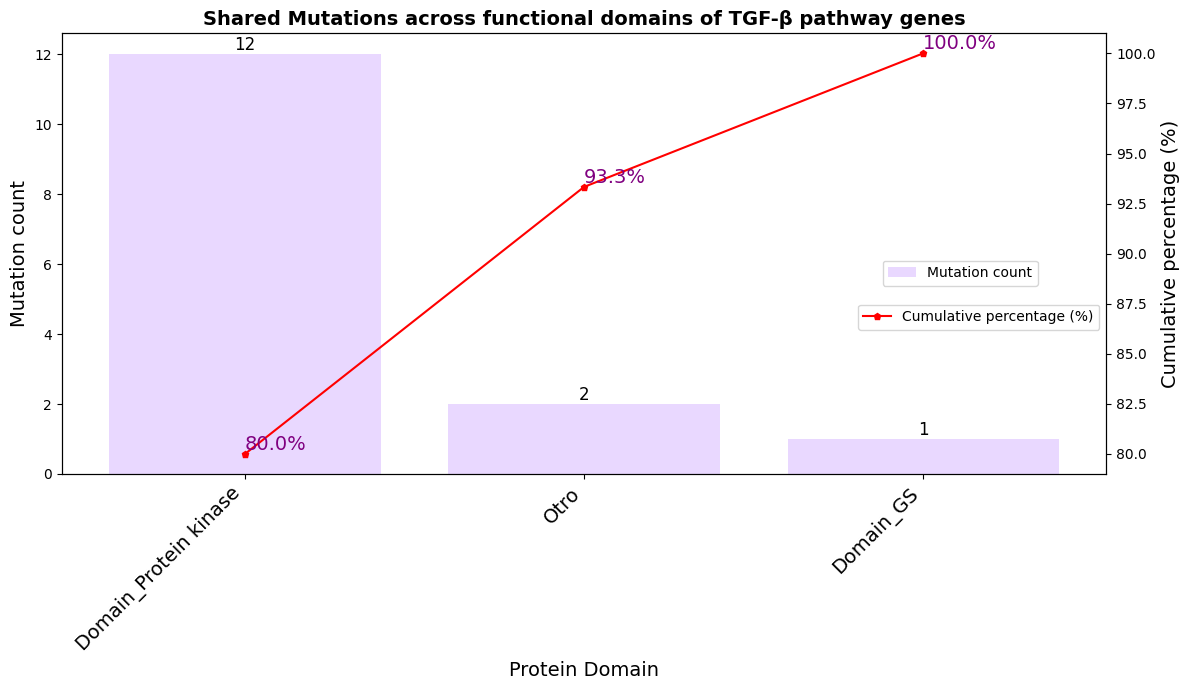

In [26]:
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

#GENERAL CONFIGURATION PARAMETERS
df = merge_miss                                                           # Input dataset
count = "HGVSp_Short"                                                  # Target metric for quantification (Y-axis)
grupo = "Dominio"                                                      # Categorical grouping feature (X-axis)
mutation_counts = df.groupby(grupo, as_index=False)[count].nunique()   # Compute distinct variant occurrences

# AXIS LABELS AND TITLES 
ylabel = 'Mutation count'
ylabel2 = 'Cumulative percentage (%)'
set_title = 'Shared Mutations across functional domains of TGF-β pathway genes'
set_xlabel = 'Protein Domain'
leyenda_2 = 'Cumulative percentage (%)'
leyenda_count = 'Mutation count'

# PALETTE 
color_bar = "#e9d8ffff"
color_linea = "red"
numero_acumulacion = 'purple'

# EXPORT SETTINGS 
GUARDAR_GRAFICO = True
FORMATO_IMAGEN = "svg"  # File extension option: 'png' or 'svg'
DPI = 600               # Raster resolution metric (evaluated if FORMATO_IMAGEN == 'png')
NOMBRE_IMAGEN = "crossroad_domain_tgfb"
RUTA = f"../pictures/{NOMBRE_IMAGEN}.{FORMATO_IMAGEN}"

# Sort categorical counts in descending order
mutation_counts.sort_values(by=count, ascending=False, inplace=True)
mutation_counts.reset_index(drop=True, inplace=True)

# Compute cumulative relative frequencies
mutation_counts['relativa_acum_porcentual'] = mutation_counts[count].cumsum() / mutation_counts[count].sum() * 100

# Initialize figure layout
fig, ax = plt.subplots(figsize=(12, 7))

# Plot absolute distribution frequencies using a bar chart canvas
bars = ax.bar(mutation_counts[grupo], mutation_counts[count], color=color_bar, label=leyenda_count)

# Secondary twin Y-axis configuration for cumulative frequency plotting
ax2 = ax.twinx()
ax2.plot(mutation_counts[grupo], mutation_counts['relativa_acum_porcentual'], color=color_linea, marker="p", ms=5, label=leyenda_2)

# Label structural bars with absolute sequence frequency values
for bar in bars:
    height = bar.get_height()
    ax.text(
        bar.get_x() + bar.get_width() / 2, 
        height, 
        f'{int(height)}', 
        ha='center', 
        va='bottom', 
        color='black', 
        fontsize=12
    )

# Annotate cumulative trajectory curve with percentage labels
for i, value in enumerate(mutation_counts["relativa_acum_porcentual"]):
    ax2.text(
        i, 
        value, 
        f'{value:.1f}%', 
        ha='left', 
        va='bottom', 
        color=numero_acumulacion, 
        fontsize=14
    )

# Format axis boundaries, markers, and text styling
ax.set_ylabel(ylabel, fontsize=14)
ax2.set_ylabel(ylabel2, fontsize=14)
ax.set_title(set_title, fontsize=14, fontweight="bold")
ax.set_xlabel(set_xlabel, fontsize=14)

# Format categorical X-axis marker text properties
ax.set_xticks(range(len(mutation_counts[grupo])))
ax.set_xticklabels(mutation_counts[grupo], rotation=45, ha="right", fontsize=14)

# Assemble multi-axis canvas legends
ax.legend(loc='best', bbox_to_anchor=(0.941, 0.5))
ax2.legend(loc='best', bbox_to_anchor=(1, 0.4))

# Optimize canvas dimensions to prevent clipping boundaries
plt.tight_layout()

# Execute conditional graphics export protocols
if GUARDAR_GRAFICO:
    if FORMATO_IMAGEN == "png":
        plt.savefig(RUTA, format="png", dpi=DPI, bbox_inches='tight')
    else:
        plt.savefig(RUTA, format=FORMATO_IMAGEN, bbox_inches='tight')

plt.show()


In [23]:
df_cancer

,Patient_ID,Tumor_Sample_Barcode,Hugo_Symbol,Chromosome,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,HGVSc,HGVSp_Short,HGVSp,Project_ID,cancer_type,Dominio,Rango
0,TCGA-BH-A0HF,TCGA-BH-A0HF-TUMOR,ACVR2A,chr2,Missense_Mutation,Single base substitution,C,T,chr2:g.147915234C>T,P83L,p.?,TCGA-BRCA,Breast,Otro,None
1,TCGA-E9-A2JT,TCGA-E9-A2JT-TUMOR,ACVRL1,chr12,Missense_Mutation,Single base substitution,G,A,chr12:g.51914483G>A,E50K,p.?,TCGA-BRCA,Breast,Otro,None
2,TCGA-BH-A1F2,TCGA-BH-A1F2-TUMOR,ACVR2A,chr2,Missense_Mutation,Single base substitution,A,T,chr2:g.147918475A>T,N282I,p.?,TCGA-BRCA,Breast,Domain_Protein kinase,192-485
3,TCGA-G4-6625,TCGA-G4-6625-TUMOR,TGFBR1,chr9,Missense_Mutation,Single base substitution,G,A,chr9:g.99128996G>A,R80Q,p.?,TCGA-COAD,Colon,Otro,None
4,TCGA-AR-A2LE,TCGA-AR-A2LE-TUMOR,TGFBR1,chr9,Missense_Mutation,Single base substitution,G,A,chr9:g.99128996G>A,R80Q,p.?,TCGA-BRCA,Breast,Otro,None
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
755,TCGA-EE-A2GI,TCGA-EE-A2GI-TUMOR,ACVR1C,chr2,Missense_Mutation,Single base substitution,G,A,chr2:g.157587306G>A,S62F,p.?,TCGA-SKCM,Skin,Otro,None
756,TCGA-EE-A183,TCGA-EE-A183-TUMOR,ACVR1C,chr2,Missense_Mutation,Single base substitution,C,T,chr2:g.157541152C>T,R308Q,p.?,TCGA-SKCM,Skin,Domain_Protein kinase,195-485
757,TCGA-FW-A3R5,TCGA-FW-A3R5-TUMOR,ACVR1C,chr2,Missense_Mutation,Single base substitution,G,A,chr2:g.157538649G>A,S270L,p.?,TCGA-SKCM,Skin,Domain_Protein kinase,195-485
758,TCGA-W3-AA1V,TCGA-W3-AA1V-TUMOR,BMPR1A,chr10,Missense_Mutation,Single base substitution,G,A,chr10:g.86912317G>A,G203E,p.?,TCGA-SKCM,Skin,Otro,None


In [28]:
merge_miss[merge_miss["Hugo_Symbol"]=="TGFBR2"]

,Patient_ID,Tumor_Sample_Barcode,Hugo_Symbol,Chromosome,Variant_Classification,Variant_Type,Reference_Allele,Tumor_Seq_Allele2,HGVSc,HGVSp_Short,...,Germline classification,GRCh38Chromosome,GRCh38Location,VariationID,AlleleID(s),dbSNP ID,Canonical SPDI,Orphanet_Match,Dominio,Rango
0,TCGA-D5-6931,TCGA-D5-6931-TUMOR,TGFBR2,chr3,Missense_Mutation,Single base substitution,C,T,chr3:g.30691477C>T,R528C,...,Pathogenic,30.0,30691477,12512,27551,rs104893810,NC_000003.12:30691476:C:T,Sin coincidencias,Domain_Protein kinase,244-544
1,TCGA-D5-6931,TCGA-D5-6931-TUMOR,TGFBR2,chr3,Missense_Mutation,Single base substitution,C,T,chr3:g.30691477C>T,R528C,...,Pathogenic,30.0,30691477,12512,27551,rs104893810,NC_000003.12:30691476:C:T,Loeys-Dietz syndrome,Domain_Protein kinase,244-544
2,TCGA-D5-6931,TCGA-D5-6931-TUMOR,TGFBR2,chr3,Missense_Mutation,Single base substitution,C,T,chr3:g.30691477C>T,R528C,...,Pathogenic,30.0,30691477,12512,27551,rs104893810,NC_000003.12:30691476:C:T,Familial thoracic aortic aneurysm and aortic d...,Domain_Protein kinase,244-544
3,TCGA-D5-6931,TCGA-D5-6931-TUMOR,TGFBR2,chr3,Missense_Mutation,Single base substitution,C,T,chr3:g.30691477C>T,R528C,...,Pathogenic,30.0,30691477,12512,27551,rs104893810,NC_000003.12:30691476:C:T,Loeys-Dietz syndrome,Domain_Protein kinase,244-544
4,TCGA-D5-6931,TCGA-D5-6931-TUMOR,TGFBR2,chr3,Missense_Mutation,Single base substitution,C,T,chr3:g.30691477C>T,R528C,...,Pathogenic,30.0,30691477,12512,27551,rs104893810,NC_000003.12:30691476:C:T,Sin coincidencias,Domain_Protein kinase,244-544
5,TCGA-44-2668,TCGA-44-2668-TUMOR,TGFBR2,chr3,Missense_Mutation,Single base substitution,C,T,chr3:g.30691477C>T,R528C,...,Pathogenic,30.0,30691477,12512,27551,rs104893810,NC_000003.12:30691476:C:T,Sin coincidencias,Domain_Protein kinase,244-544
6,TCGA-44-2668,TCGA-44-2668-TUMOR,TGFBR2,chr3,Missense_Mutation,Single base substitution,C,T,chr3:g.30691477C>T,R528C,...,Pathogenic,30.0,30691477,12512,27551,rs104893810,NC_000003.12:30691476:C:T,Loeys-Dietz syndrome,Domain_Protein kinase,244-544
7,TCGA-44-2668,TCGA-44-2668-TUMOR,TGFBR2,chr3,Missense_Mutation,Single base substitution,C,T,chr3:g.30691477C>T,R528C,...,Pathogenic,30.0,30691477,12512,27551,rs104893810,NC_000003.12:30691476:C:T,Familial thoracic aortic aneurysm and aortic d...,Domain_Protein kinase,244-544
8,TCGA-44-2668,TCGA-44-2668-TUMOR,TGFBR2,chr3,Missense_Mutation,Single base substitution,C,T,chr3:g.30691477C>T,R528C,...,Pathogenic,30.0,30691477,12512,27551,rs104893810,NC_000003.12:30691476:C:T,Loeys-Dietz syndrome,Domain_Protein kinase,244-544
9,TCGA-44-2668,TCGA-44-2668-TUMOR,TGFBR2,chr3,Missense_Mutation,Single base substitution,C,T,chr3:g.30691477C>T,R528C,...,Pathogenic,30.0,30691477,12512,27551,rs104893810,NC_000003.12:30691476:C:T,Sin coincidencias,Domain_Protein kinase,244-544


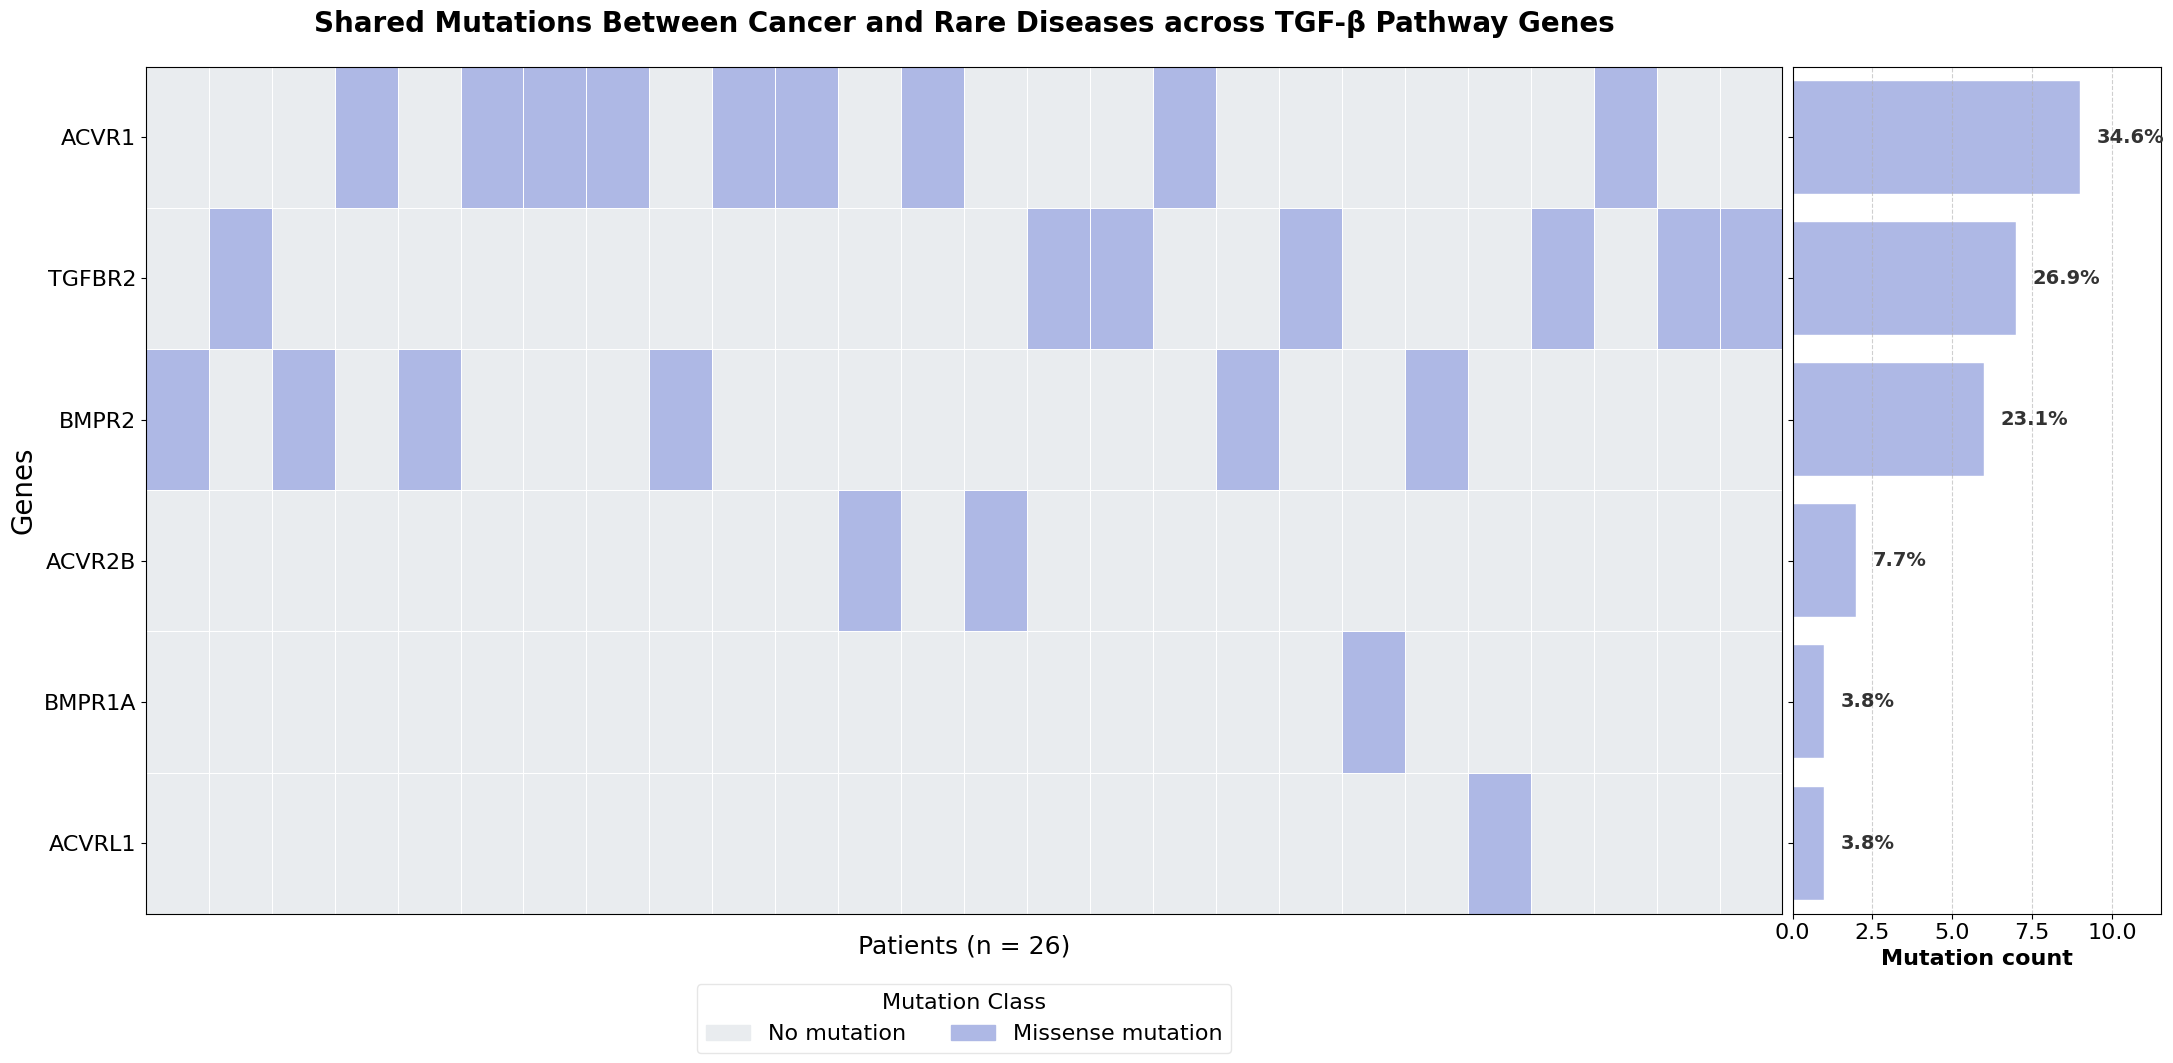

In [25]:
import matplotlib.patches as mpatches
from matplotlib.colors import ListedColormap

# Define color palette for mutation classes
color_dict = {
    "No mutation":        {"val": 0, "color": "#e9ecef"},
    "Missense_Mutation":  {"val": 1, "color": "#AEB8E5"},
}

# Subselect critical genomic coordinates and compute variant occurrences
mut_df = merge_miss[["Patient_ID", "Hugo_Symbol", "Variant_Classification", "HGVSp_Short"]]
mut_df = mut_df.groupby(["Patient_ID", "Hugo_Symbol", "Variant_Classification"])["HGVSp_Short"].count().reset_index()

# Drop rows with missing critical annotations
df_maf = mut_df.dropna(subset=['Hugo_Symbol', 'Patient_ID', 'Variant_Classification']).copy()

# Sort genes by mutation frequency
gene_counts = df_maf['Hugo_Symbol'].value_counts().sort_values(ascending=True)
genes_ordenados = gene_counts.index.tolist()

# Construct the mutation matrix
df_matrix = df_maf.pivot_table(
    index='Hugo_Symbol', 
    columns='Patient_ID', 
    values='Variant_Classification',
    aggfunc=lambda x: x.iloc[0]
).fillna("No mutation")

# Map categorical classifications to numerical values with a safe default fallback
df_matrix_num = df_matrix.map(lambda x: color_dict.get(x, color_dict["No mutation"])["val"])
df_matrix_num = df_matrix_num.reindex(genes_ordenados)

# Sort patients hierarchically to generate the characteristic cascade pattern
pacientes_ordenados = df_matrix_num.T.index
df_matrix_num = df_matrix_num[pacientes_ordenados]

num_total_pacientes = df_matrix_num.shape[1]

# Generate the categorical colormap
colores_lista = [c["color"] for c in sorted(color_dict.values(), key=lambda x: x["val"])]
cmap_onco = ListedColormap(colores_lista)

# Initialize plot subplots
fig, (ax_main, ax_right) = plt.subplots(
    1, 2, 
    figsize=(26, 11), 
    gridspec_kw={'width_ratios': [4, 0.9]}, 
    sharey=True
)
fig.subplots_adjust(wspace=0.01)

# Plot primary mutation matrix using a specialized discrete mesh grid
ax_main.pcolormesh(
    df_matrix_num.values, 
    cmap=cmap_onco, 
    edgecolors='white', 
    linewidths=0.4, 
    vmin=0, 
    vmax=len(colores_lista)-1
)

ax_main.set_title("Shared Mutations Between Cancer and Rare Diseases across TGF-β Pathway Genes", fontsize=20, pad=25, weight='bold')
ax_main.set_xticks([]) 
ax_main.set_xlabel(f"Patients (n = {num_total_pacientes})", fontsize=18, labelpad=15)
ax_main.set_ylabel("Genes", fontsize=20)
ax_main.set_yticks(np.arange(df_matrix_num.shape[0]) + 0.5)
ax_main.set_yticklabels(df_matrix_num.index, fontsize=16)

# Calculate and plot stacked mutation frequencies
y_positions = np.arange(len(genes_ordenados)) + 0.5
left_acumulado = np.zeros(len(genes_ordenados))

for val_num in range(1, len(colores_lista)):
    color_actual = colores_lista[val_num]
    conteos_por_gen = (df_matrix_num == val_num).sum(axis=1).values
    
    ax_right.barh(
        y_positions, 
        conteos_por_gen, 
        left=left_acumulado, 
        color=color_actual, 
        edgecolor='white',   
        linewidth=0.3,
        height=0.8
    )
    left_acumulado += conteos_por_gen

# Calculate absolute counts and cohort percentages for annotations
conteos_totales_gen = (df_matrix_num > 0).sum(axis=1).values
frecuencia_total_gen = (conteos_totales_gen / num_total_pacientes) * 100

# Annotate cohort penetrancy percentages alongside absolute bars
for i, count in enumerate(conteos_totales_gen):
    pct = frecuencia_total_gen[i]
    ax_right.text(
        count + 0.5, 
        y_positions[i], 
        f"{pct:.1f}%", 
        va='center', 
        ha='left', 
        fontsize=14, 
        weight='bold',
        color='#333333'
    )

# Format side bar chart axes using discrete absolute counts
ax_right.grid(axis='x', linestyle='--', alpha=0.6, zorder=0)
ax_right.set_xlabel("Mutation count", fontsize=16, weight='bold')
ax_right.set_xlim(0, max(conteos_totales_gen) * 1.28) 
ax_right.set_yticks(y_positions)
ax_right.tick_params(axis='x', which='both', labelsize=16)

# Synchronize subplot vertical boundaries
ax_main.set_ylim(0, df_matrix_num.shape[0])
ax_right.set_ylim(0, df_matrix_num.shape[0])

# Construct and position the mutation class legend
leyenda_parches = []
nombres_vistos = set()
for name, info in color_dict.items():
    clean_name = name.replace("_", " ").capitalize()
    if info["val"] not in nombres_vistos:
        leyenda_parches.append(mpatches.Patch(color=info["color"], label=clean_name))
        nombres_vistos.add(info["val"])

ax_main.legend(
    handles=leyenda_parches, 
    loc='upper center', 
    bbox_to_anchor=(0.5, -0.07), 
    ncol=4, 
    title="Mutation Class", 
    title_fontsize=16,
    fontsize=16, 
    frameon=True,
    facecolor='white',
    edgecolor='#e0e0e0'
)

# Export publication-ready graphics vectors
plt.savefig("../pictures/oncoplot_crossroad.png", dpi=600, bbox_inches='tight')
plt.savefig("../pictures/oncoplot_crossroad.svg", bbox_inches='tight')
plt.show()